# K-nearest neighbours on the Iris dataset

The Iris dataset has 150 flowers from three species, each described by four measurements of its sepals and petals. The goal is to predict the species from those measurements with k-nearest neighbours (KNN): a new flower gets the species shared by most of its k closest flowers in the training set.

In [1]:
from sklearn.datasets import load_iris

iris = load_iris()

print("Numărul de exemple și caracteristici (rânduri, coloane):", iris.data.shape)
print("Denumirile atributelor (coloanelor):", iris.feature_names)
print("Numele claselor (speciilor):", iris.target_names)

Numărul de exemple și caracteristici (rânduri, coloane): (150, 4)
Denumirile atributelor (coloanelor): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Numele claselor (speciilor): ['setosa' 'versicolor' 'virginica']


## Train/test split and scaling

20% of the flowers are held back for testing. KNN works with distances, so a feature measured in bigger numbers would outweigh the others. `StandardScaler` rescales every feature to mean 0 and standard deviation 1. It learns those numbers from the training set only and applies the same ones to the test set.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)

print("Forma datelor de antrenament:", X_train.shape)
print("Forma datelor de testare:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nPrimele 3 exemple ÎNAINTE de scalare:\n", X_train[:3])
print("\nPrimele 3 exemple DUPĂ scalare:\n", X_train_scaled[:3])

Forma datelor de antrenament: (120, 4)
Forma datelor de testare: (30, 4)

Primele 3 exemple ÎNAINTE de scalare:
 [[6.4 3.1 5.5 1.8]
 [5.2 4.1 1.5 0.1]
 [5.4 3.4 1.5 0.4]]

Primele 3 exemple DUPĂ scalare:
 [[ 0.70202101  0.13405605  1.02897177  0.84421264]
 [-0.73597366  2.53505988 -1.25129808 -1.41588419]
 [-0.49630788  0.8543572  -1.25129808 -1.01704357]]


## A first model with k = 3

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print(f"Acuratețea modelului cu k=3: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Matricea de confuzie:\n", confusion_matrix(y_test, y_pred))
print("\nRaport de clasificare:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

Acuratețea modelului cu k=3: 96.67%

Matricea de confuzie:
 [[ 9  0  0]
 [ 0  8  0]
 [ 0  1 12]]

Raport de clasificare:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.89      1.00      0.94         8
   virginica       1.00      0.92      0.96        13

    accuracy                           0.97        30
   macro avg       0.96      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## Choosing k

A small k follows the training data too closely, and a large one blurs the border between species. The loop trains one model for each k from 1 to 15 and plots its test accuracy. With only 30 test flowers, one mistake moves the accuracy by about 3 points, so cross-validation on the training set would be a fairer way to pick k.

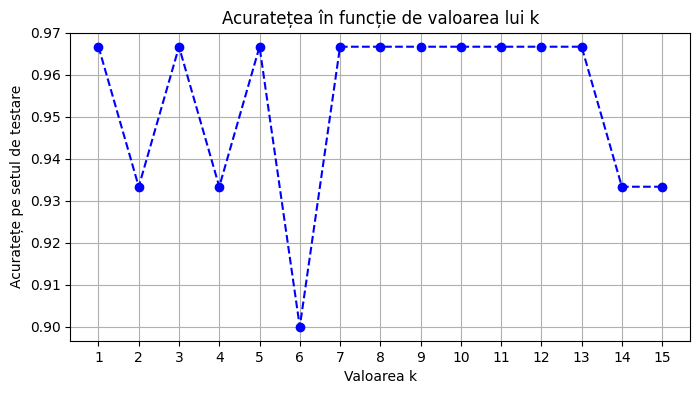

In [4]:
import matplotlib.pyplot as plt

accuracies = []
k_values = range(1, 16)

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    score = knn_temp.score(X_test_scaled, y_test)
    accuracies.append(score)

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='dashed', color='b')
plt.title('Acuratețea în funcție de valoarea lui k')
plt.xlabel('Valoarea k')
plt.ylabel('Acuratețe pe setul de testare')
plt.xticks(k_values)
plt.grid(True)
plt.show()

## Why it works so well

Petal length and width alone almost separate the three species. Setosa sits far away from the other two, while versicolor and virginica overlap a little. The single mistake above is a virginica that the model took for a versicolor.

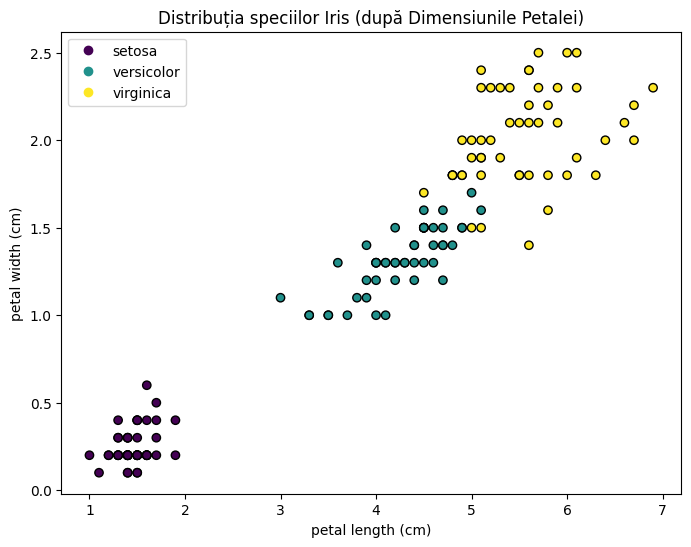

In [5]:
X_petala = X[:, 2:4]

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_petala[:, 0], X_petala[:, 1], c=y, cmap='viridis', edgecolor='k')

plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title('Distribuția speciilor Iris (după Dimensiunile Petalei)')

plt.legend(handles=scatter.legend_elements()[0], labels=iris.target_names.tolist())
plt.show()

## Classifying a new flower

The first version read the measurements with `input()`, which stops the notebook when it runs from top to bottom. It is now a function called on three example flowers.

In [6]:
def prezice_specia(sepal_length, sepal_width, petal_length, petal_width):
    floare_noua = [[sepal_length, sepal_width, petal_length, petal_width]]
    floare_noua_scaled = scaler.transform(floare_noua)
    pred_index = knn.predict(floare_noua_scaled)[0]
    return iris.target_names[pred_index]


print("--- TESTEAZĂ O FLOARE NOUĂ ---")
for masuratori in [(5.1, 3.5, 1.4, 0.2), (6.0, 2.9, 4.5, 1.5), (6.9, 3.1, 5.4, 2.1)]:
    print(f"{masuratori} => {prezice_specia(*masuratori).upper()}")

--- TESTEAZĂ O FLOARE NOUĂ ---
(5.1, 3.5, 1.4, 0.2) => SETOSA
(6.0, 2.9, 4.5, 1.5) => VERSICOLOR
(6.9, 3.1, 5.4, 2.1) => VIRGINICA
